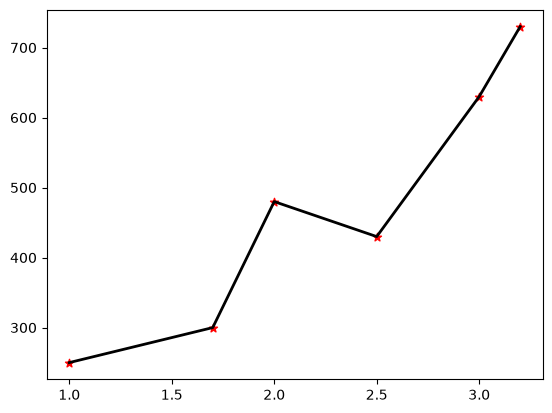

In [7]:
import math, copy
import numpy as np
import matplotlib.pyplot as plt



# lets make a linear data set with a single parameter 
x_train = np.array([1.0, 1.7, 2.0, 2.5, 3.0, 3.2])
y_train = np.array([250, 300, 480,  430,   630, 730,])

plt.plot(x_train, y_train, color = 'black', linestyle = "-", linewidth = 2 )
plt.scatter(x_train, y_train, color = 'red', marker = "*" )
plt.show()

In [8]:
def cost (x, y, w, b):
    m = x.shape[0]
    cost_sum = 0

    for i in  range(m):
        f_wb = w*x[i] + b
        cost = (f_wb - y[i])**2
        cost_sum = cost_sum + cost
    total_cost = (1/(2*m))*cost_sum
    return total_cost

print(cost(x_train, y_train, 200, 25))
    
    

1762.5


In [9]:
def model_output(x, w , b):

    m = x.shape[0]
    y_hat = np.zeros(m)
    for i in range(m):
        y_hat[i] = w*x[i] + b
    return y_hat

print(model_output(x_train, 200, 25))

[225. 365. 425. 525. 625. 665.]


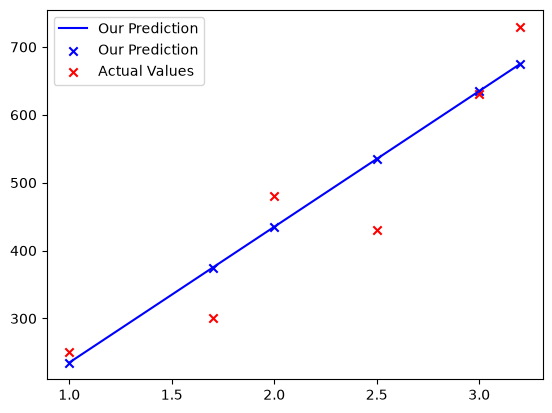

In [22]:
temp_y_train = model_output(x_train, 200, 35)
plt.plot(x_train, temp_y_train, c='b',label='Our Prediction')
plt.scatter(x_train, temp_y_train, marker='x', c='b',label='Our Prediction')

plt.scatter(x_train, y_train, marker='x', c='r',label='Actual Values')
plt.legend()
plt.show()


In [11]:
# compute gradient: partial derivative of j(w,b) or slope of j(w,b)

def compute_gradient (x, y, w, b):

    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb = w * x[i] + b
        dj_dw_i = (f_wb - y[i]) * x[i]
        dj_db_i = f_wb - y[i]
        dj_dw += dj_dw_i
        dj_db += dj_db_i

    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_dw, dj_db

In [15]:
def gradient_descent (x, y, w_in, b_in, num_iters,  alpha, gradient, cost):

    J_history = []
    P_history = []

    w = w_in
    b = b_in

    for i in range(num_iters):
        dj_dw, dj_db = gradient(x, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i < 100000 : 
            J_history.append( cost(x, y, w, b))
            P_history.append([w,b])

        if i% math.ceil(num_iters/10) == 0:
            print(f"Iteration {i:4}: Cost {J_history[-1]:0.2e} ",
                  f"dj_dw: {dj_dw: 0.3e}, dj_db: {dj_db: 0.3e}  ",
                  f"w: {w: 0.3e}, b:{b: 0.5e}")
 
    return w, b, J_history, P_history


In [16]:
w_init = 0
b_init = 0

iterations = 10000
tmp_alpha = 1.0e-2

w_final, b_final, J_hist, P_hist = gradient_descent(x_train ,y_train, w_init, b_init, iterations, tmp_alpha, 
                                                      compute_gradient, cost)
print(f"(w,b) found by gradient descent: ({w_final:8.4f},{b_final:8.4f})")

Iteration    0: Cost 1.09e+05  dj_dw: -1.170e+03, dj_db: -4.700e+02   w:  1.170e+01, b: 4.70000e+00
Iteration 1000: Cost 1.78e+03  dj_dw: -1.060e+00, dj_db:  2.599e+00   w:  1.974e+02, b: 3.16325e+01
Iteration 2000: Cost 1.74e+03  dj_dw: -4.357e-01, dj_db:  1.068e+00   w:  2.045e+02, b: 1.44256e+01
Iteration 3000: Cost 1.74e+03  dj_dw: -1.790e-01, dj_db:  4.388e-01   w:  2.074e+02, b: 7.35495e+00
Iteration 4000: Cost 1.74e+03  dj_dw: -7.357e-02, dj_db:  1.803e-01   w:  2.085e+02, b: 4.44950e+00
Iteration 5000: Cost 1.74e+03  dj_dw: -3.023e-02, dj_db:  7.410e-02   w:  2.090e+02, b: 3.25559e+00
Iteration 6000: Cost 1.74e+03  dj_dw: -1.242e-02, dj_db:  3.045e-02   w:  2.092e+02, b: 2.76500e+00
Iteration 7000: Cost 1.74e+03  dj_dw: -5.104e-03, dj_db:  1.251e-02   w:  2.093e+02, b: 2.56340e+00
Iteration 8000: Cost 1.74e+03  dj_dw: -2.097e-03, dj_db:  5.141e-03   w:  2.093e+02, b: 2.48056e+00
Iteration 9000: Cost 1.74e+03  dj_dw: -8.619e-04, dj_db:  2.113e-03   w:  2.094e+02, b: 2.44652e+00


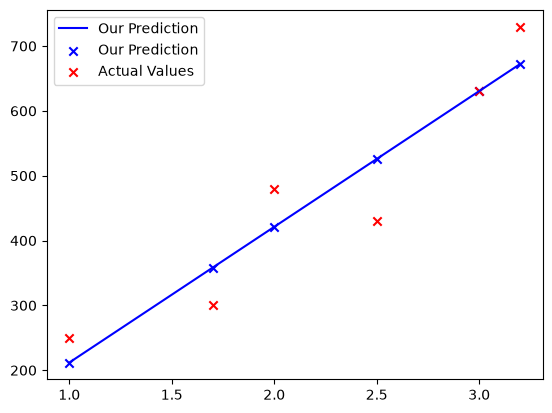

In [23]:
temp_y_train = model_output(x_train, 209.3590,  2.4325)
plt.plot(x_train, temp_y_train, c='b',label='Our Prediction')
plt.scatter(x_train, temp_y_train, marker='x', c='b',label='Our Prediction')

plt.scatter(x_train, y_train, marker='x', c='r',label='Actual Values')
plt.legend()
plt.show()